# Banana Disease Classification: From Neural Network to Deployment

Predictive Analytics report: *Introduction to Neural Networks & Deep Learning* and *Model Deployment & MLOps Basics*.

Run on a free GPU (Colab or Kaggle). Flow: load data, baseline CNN, transfer learning, evaluate, deploy to a Hugging Face Space.

In [1]:
!pip install -q datasets huggingface_hub scikit-learn onnx onnxruntime

## 1. Setup

In [2]:
from huggingface_hub import notebook_login

# The dataset is gated: accept its conditions on the dataset page first
notebook_login()

In [3]:
import os
import json
import random
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Hyperparameters and settings
DATASET_REPO = "Saon110/bd-crop-vegetable-plant-disease-dataset"
DATA_DIR = "banana_data"
IMAGES_PER_CLASS = {"train": 500, "valid": 100, "test": 100}
NUM_BANANA_CLASSES = 9
IMAGE_SIZE = 224
BATCH_SIZE = 32
BASELINE_EPOCHS = 10
BASELINE_LEARNING_RATE = 1e-3
TRANSFER_EPOCHS = 5
TRANSFER_LEARNING_RATE = 1e-3
SEED = 42

# Same seed every run so results can be reproduced
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## 2. Load the banana subset

In [4]:
# Streaming avoids downloading the full 19 GB dataset.
# If the data is not sorted by class, this scan can take a while.
for split_name, images_per_class in IMAGES_PER_CLASS.items():
    stream = load_dataset(DATASET_REPO, split=split_name, streaming=True)

    # "label" is a plain number here, so the "label_name" text column is used instead
    saved_counts = {}

    for example in stream:
        class_name = example["label_name"]

        if not class_name.startswith("Banana"):
            continue
        if saved_counts.get(class_name, 0) >= images_per_class:
            continue

        class_folder = os.path.join(DATA_DIR, split_name, class_name)
        os.makedirs(class_folder, exist_ok=True)

        # Resize once here so training does not repeat it every epoch
        image = example["image"].convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
        image_number = saved_counts.get(class_name, 0)
        image.save(os.path.join(class_folder, f"{image_number}.jpg"))
        saved_counts[class_name] = image_number + 1

        all_classes_full = (len(saved_counts) == NUM_BANANA_CLASSES
                            and all(count >= images_per_class for count in saved_counts.values()))
        if all_classes_full:
            break

    print(split_name, saved_counts)

train {'Banana_Black_Pitting_or_Banana_Rust': 500, 'Banana_Crown_Rot': 199, 'Banana_Healthy': 120, 'Banana_fungal_disease': 500, 'Banana_leaf_Banana_Scab_Moth': 70, 'Banana_leaf_Black_Sigatoka': 500, 'Banana_leaf_Healthy': 500, 'Banana_leaf__Black_Leaf_Streak': 220, 'Banana_leaf__Panama_Disease.': 196}
valid {'Banana_Black_Pitting_or_Banana_Rust': 100, 'Banana_Crown_Rot': 57, 'Banana_Healthy': 34, 'Banana_fungal_disease': 100, 'Banana_leaf_Banana_Scab_Moth': 20, 'Banana_leaf_Black_Sigatoka': 100, 'Banana_leaf_Healthy': 100, 'Banana_leaf__Black_Leaf_Streak': 63, 'Banana_leaf__Panama_Disease.': 56}
test {'Banana_Black_Pitting_or_Banana_Rust': 100, 'Banana_Crown_Rot': 29, 'Banana_Healthy': 18, 'Banana_fungal_disease': 100, 'Banana_leaf_Banana_Scab_Moth': 10, 'Banana_leaf_Black_Sigatoka': 85, 'Banana_leaf_Healthy': 100, 'Banana_leaf__Black_Leaf_Streak': 32, 'Banana_leaf__Panama_Disease.': 28}


In [5]:
# ImageNet mean/std because MobileNetV2 later was pretrained with these
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

# Flip only on training data to add variety without touching evaluation data
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    normalize,
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    normalize,
])

train_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_transform)
valid_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "valid"), transform=eval_transform)
test_dataset = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

class_names = train_dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)
print("Train / valid / test:", len(train_dataset), len(valid_dataset), len(test_dataset))

Classes: ['Banana_Black_Pitting_or_Banana_Rust', 'Banana_Crown_Rot', 'Banana_Healthy', 'Banana_fungal_disease', 'Banana_leaf_Banana_Scab_Moth', 'Banana_leaf_Black_Sigatoka', 'Banana_leaf_Healthy', 'Banana_leaf__Black_Leaf_Streak', 'Banana_leaf__Panama_Disease.']
Train / valid / test: 2805 630 502


## 3. Look at the data

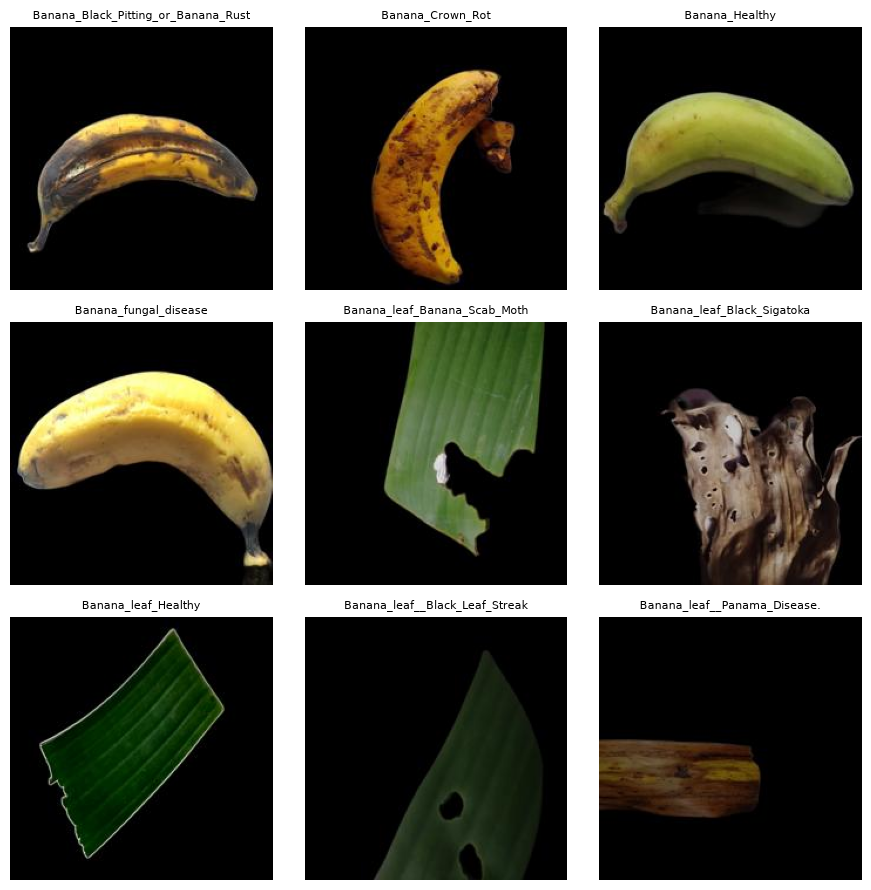

In [6]:
# Quick check that images and labels look right, and how fruit vs leaf classes differ
figure, axes = plt.subplots(3, 3, figsize=(9, 9))

for class_index, axis in enumerate(axes.flatten()):
    class_folder = os.path.join(DATA_DIR, "train", class_names[class_index])
    first_image_name = sorted(os.listdir(class_folder))[0]
    image = plt.imread(os.path.join(class_folder, first_image_name))
    axis.imshow(image)
    axis.set_title(class_names[class_index], fontsize=8)
    axis.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Duplicate images shared between train and test would inflate test accuracy
train_hashes = set()
for image_path, _ in train_dataset.samples:
    with open(image_path, "rb") as image_file:
        train_hashes.add(hashlib.md5(image_file.read()).hexdigest())

overlap_count = 0
for image_path, _ in test_dataset.samples:
    with open(image_path, "rb") as image_file:
        if hashlib.md5(image_file.read()).hexdigest() in train_hashes:
            overlap_count += 1

print("Test images that exactly match a train image:", overlap_count)

Test images that exactly match a train image: 20


## 4. Baseline: small CNN from scratch

Three conv blocks, then one linear layer that outputs a score per class.

In [8]:
baseline_model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    # Average each feature map to one number so the linear layer stays small
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(64, num_classes),
).to(device)

# Cross-entropy is the standard loss for multi-class classification
loss_function = nn.CrossEntropyLoss()
optimizer = optim.Adam(baseline_model.parameters(), lr=BASELINE_LEARNING_RATE)

baseline_valid_accuracies = []

for epoch in range(BASELINE_EPOCHS):
    baseline_model.train()
    epoch_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        scores = baseline_model(images)
        loss = loss_function(scores, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    # Validation data tells us if the model generalizes, not just memorizes
    baseline_model.eval()
    correct_count = 0
    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)
            predictions = baseline_model(images).argmax(dim=1)
            correct_count += (predictions == labels).sum().item()

    valid_accuracy = correct_count / len(valid_dataset)
    baseline_valid_accuracies.append(valid_accuracy)
    print(f"Epoch {epoch + 1}: loss {epoch_loss / len(train_loader):.4f}, valid accuracy {valid_accuracy:.3f}")

Epoch 1: loss 1.7812, valid accuracy 0.383
Epoch 2: loss 1.3809, valid accuracy 0.449
Epoch 3: loss 1.2506, valid accuracy 0.492
Epoch 4: loss 1.1297, valid accuracy 0.548
Epoch 5: loss 1.0537, valid accuracy 0.546
Epoch 6: loss 1.0106, valid accuracy 0.541
Epoch 7: loss 0.9658, valid accuracy 0.579
Epoch 8: loss 0.9379, valid accuracy 0.562
Epoch 9: loss 0.9409, valid accuracy 0.578
Epoch 10: loss 0.9188, valid accuracy 0.578


## 5. Transfer learning: pretrained MobileNetV2

Reuse features learned on ImageNet and train only a new final layer. MobileNetV2 is small enough to run on a free CPU Space later.

In [9]:
transfer_model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Freeze the pretrained layers so only the new head learns
for parameter in transfer_model.features.parameters():
    parameter.requires_grad = False

transfer_model.classifier[1] = nn.Linear(transfer_model.last_channel, num_classes)
transfer_model = transfer_model.to(device)

# Only the new head is given to the optimizer
optimizer = optim.Adam(transfer_model.classifier.parameters(), lr=TRANSFER_LEARNING_RATE)

transfer_valid_accuracies = []

for epoch in range(TRANSFER_EPOCHS):
    transfer_model.train()
    # Keep frozen layers in eval mode so their batch norm statistics do not drift
    transfer_model.features.eval()
    epoch_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        scores = transfer_model(images)
        loss = loss_function(scores, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    transfer_model.eval()
    correct_count = 0
    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)
            predictions = transfer_model(images).argmax(dim=1)
            correct_count += (predictions == labels).sum().item()

    valid_accuracy = correct_count / len(valid_dataset)
    transfer_valid_accuracies.append(valid_accuracy)
    print(f"Epoch {epoch + 1}: loss {epoch_loss / len(train_loader):.4f}, valid accuracy {valid_accuracy:.3f}")

Epoch 1: loss 1.1352, valid accuracy 0.648
Epoch 2: loss 0.6855, valid accuracy 0.717
Epoch 3: loss 0.5872, valid accuracy 0.716
Epoch 4: loss 0.5440, valid accuracy 0.721
Epoch 5: loss 0.5094, valid accuracy 0.743


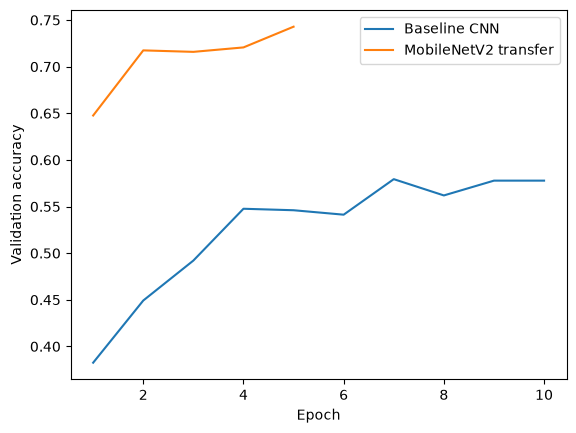

In [10]:
plt.plot(range(1, BASELINE_EPOCHS + 1), baseline_valid_accuracies, label="Baseline CNN")
plt.plot(range(1, TRANSFER_EPOCHS + 1), transfer_valid_accuracies, label="MobileNetV2 transfer")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.legend()
plt.show()

## 6. Evaluate on the test set

In [11]:
# Test data was never used for training or choosing settings, so this is the honest score
baseline_model.eval()
transfer_model.eval()

true_labels = []
baseline_predictions = []
transfer_predictions = []
transfer_confidences = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        baseline_scores = baseline_model(images)
        transfer_scores = transfer_model(images)
        transfer_probabilities = torch.softmax(transfer_scores, dim=1)

        true_labels.extend(labels.tolist())
        baseline_predictions.extend(baseline_scores.argmax(dim=1).cpu().tolist())
        transfer_predictions.extend(transfer_scores.argmax(dim=1).cpu().tolist())
        transfer_confidences.extend(transfer_probabilities.max(dim=1).values.cpu().tolist())

true_labels = np.array(true_labels)
baseline_predictions = np.array(baseline_predictions)
transfer_predictions = np.array(transfer_predictions)

print("Baseline test accuracy:", (baseline_predictions == true_labels).mean())
print("Transfer test accuracy:", (transfer_predictions == true_labels).mean())
print()
print(classification_report(true_labels, transfer_predictions, target_names=class_names))

Baseline test accuracy: 0.5916334661354582
Transfer test accuracy: 0.7390438247011952

                                     precision    recall  f1-score   support

Banana_Black_Pitting_or_Banana_Rust       0.52      0.43      0.47       100
                   Banana_Crown_Rot       0.61      0.66      0.63        29
                     Banana_Healthy       0.71      0.94      0.81        18
              Banana_fungal_disease       0.60      0.66      0.63       100
       Banana_leaf_Banana_Scab_Moth       1.00      1.00      1.00        10
         Banana_leaf_Black_Sigatoka       0.88      0.80      0.84        85
                Banana_leaf_Healthy       0.96      1.00      0.98       100
     Banana_leaf__Black_Leaf_Streak       1.00      0.91      0.95        32
       Banana_leaf__Panama_Disease.       0.54      0.68      0.60        28

                           accuracy                           0.74       502
                          macro avg       0.76      0.79      0.

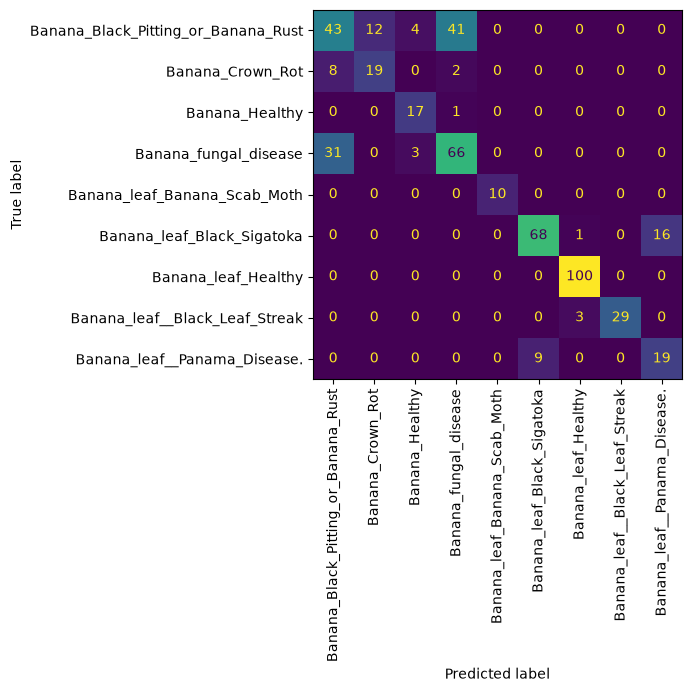

In [12]:
matrix = confusion_matrix(true_labels, transfer_predictions)
display = ConfusionMatrixDisplay(matrix, display_labels=class_names)
display.plot(xticks_rotation=90, colorbar=False)
plt.show()

## 7. Save the model

Weights go to a `model` folder (the Hub model repo). The class names also go to `deploy` for the web app.

In [13]:
os.makedirs("model", exist_ok=True)
os.makedirs("deploy", exist_ok=True)

# state_dict stores only the learned numbers, which keeps the file small
torch.save(transfer_model.state_dict(), "model/banana_mobilenet.pth")

with open("model/class_names.json", "w") as class_names_file:
    json.dump(class_names, class_names_file)
with open("deploy/class_names.json", "w") as class_names_file:
    json.dump(class_names, class_names_file)

## 8. Convert to ONNX

Hugging Face now charges for Gradio Spaces, but static Spaces are free. A static Space has no Python server, so the model runs in the visitor's browser. ONNX is the format the browser runtime reads.

In [14]:
import onnxruntime as ort

transfer_model.eval()
transfer_model.cpu()

dummy_image = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)
torch.onnx.export(
    transfer_model,
    dummy_image,
    "deploy/banana_mobilenet.onnx",
    input_names=["image"],
    output_names=["scores"],
    opset_version=13,
    dynamo=False,
)

# The converted model must give the same scores as PyTorch
session = ort.InferenceSession("deploy/banana_mobilenet.onnx")
onnx_scores = session.run(None, {"image": dummy_image.numpy()})[0]
with torch.no_grad():
    torch_scores = transfer_model(dummy_image).numpy()

print("Max difference:", np.abs(onnx_scores - torch_scores).max())
print("ONNX file size (MB):", os.path.getsize("deploy/banana_mobilenet.onnx") / 1e6)

/var/folders/8n/v66rz79524d56pr6lk03rd300000gn/T/ipykernel_14591/2294296679.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Max difference: 4.529953e-06
ONNX file size (MB): 8.914372


## 9. Deploy to a static Hugging Face Space (free)

The Space needs `index.html`, `README.md`, the ONNX file, and `class_names.json`.

In [15]:
%%writefile deploy/index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Banana Disease Classifier</title>
<script src="https://cdn.jsdelivr.net/npm/onnxruntime-web@1.17.1/dist/ort.min.js"></script>
<style>
  body { font-family: sans-serif; max-width: 480px; margin: 2rem auto; padding: 0 1rem; }
  img { max-width: 100%; margin-top: 1rem; border-radius: 8px; }
  .row { margin-top: 0.6rem; }
  .bar { background: #f5c518; height: 14px; border-radius: 7px; }
  .label { font-size: 0.9rem; margin-bottom: 2px; }
</style>
</head>
<body>
<h1>Banana Disease Classifier</h1>
<p id="statusText">Loading model...</p>
<input type="file" id="fileInput" accept="image/*" disabled>
<img id="preview" alt="">
<canvas id="canvas" width="224" height="224" hidden></canvas>
<div id="results"></div>

<script>
const IMAGE_SIZE = 224;
// Same normalization used during training
const MEAN = [0.485, 0.456, 0.406];
const STD = [0.229, 0.224, 0.225];

const statusText = document.getElementById("statusText");
const fileInput = document.getElementById("fileInput");
const preview = document.getElementById("preview");
const canvas = document.getElementById("canvas");
const results = document.getElementById("results");

let session;
let classNames;

async function loadModel() {
  // One thread because multi-threading needs browser settings a Space page does not have
  ort.env.wasm.numThreads = 1;
  const response = await fetch("class_names.json");
  classNames = await response.json();
  session = await ort.InferenceSession.create("banana_mobilenet.onnx", { executionProviders: ["wasm"] });
  statusText.textContent = "Model ready. Upload a banana photo.";
  fileInput.disabled = false;
}

function imageToTensor(image) {
  // Stretching to 224x224 matches the resize done when the training images were saved
  const context = canvas.getContext("2d");
  context.drawImage(image, 0, 0, IMAGE_SIZE, IMAGE_SIZE);
  const pixels = context.getImageData(0, 0, IMAGE_SIZE, IMAGE_SIZE).data;

  // Browser pixels are RGBA interleaved, the model wants channels-first (C, H, W)
  const planeSize = IMAGE_SIZE * IMAGE_SIZE;
  const data = new Float32Array(3 * planeSize);
  for (let i = 0; i < planeSize; i++) {
    for (let c = 0; c < 3; c++) {
      data[c * planeSize + i] = (pixels[i * 4 + c] / 255 - MEAN[c]) / STD[c];
    }
  }
  return new ort.Tensor("float32", data, [1, 3, IMAGE_SIZE, IMAGE_SIZE]);
}

async function classify(image) {
  const output = await session.run({ image: imageToTensor(image) });
  const scores = Array.from(output.scores.data);

  // Softmax turns raw scores into probabilities (subtract max for numerical stability)
  const maxScore = Math.max(...scores);
  const exps = scores.map(function (s) { return Math.exp(s - maxScore); });
  const total = exps.reduce(function (a, b) { return a + b; }, 0);
  const probabilities = exps.map(function (e) { return e / total; });

  const top3 = probabilities
    .map(function (p, i) { return { name: classNames[i], p: p }; })
    .sort(function (a, b) { return b.p - a.p; })
    .slice(0, 3);

  results.innerHTML = "";
  top3.forEach(function (item) {
    const percent = (item.p * 100).toFixed(1);
    const row = document.createElement("div");
    row.className = "row";
    row.innerHTML = '<div class="label">' + item.name + " (" + percent + '%)</div>' +
                    '<div class="bar" style="width:' + percent + '%"></div>';
    results.appendChild(row);
  });
}

fileInput.addEventListener("change", function () {
  const file = fileInput.files[0];
  if (!file) return;
  preview.onload = function () { classify(preview); };
  preview.src = URL.createObjectURL(file);
});

loadModel().catch(function (error) {
  statusText.textContent = "Could not load the model: " + error;
});
</script>
</body>
</html>

Writing deploy/index.html


In [16]:
%%writefile deploy/README.md
---
title: Banana Disease Classifier
emoji: 🍌
colorFrom: yellow
colorTo: green
sdk: static
pinned: false
---

Writing deploy/README.md


In [17]:
from huggingface_hub import HfApi

api = HfApi()
username = api.whoami()["name"]

# Model repo: versioned storage for the PyTorch weights
model_repo_id = f"{username}/banana-disease-mobilenet"
api.create_repo(repo_id=model_repo_id, repo_type="model", exist_ok=True)
api.upload_folder(folder_path="model", repo_id=model_repo_id, repo_type="model")

# Static Space: serves the web app
space_id = f"{username}/banana-disease-classifier"
api.create_repo(repo_id=space_id, repo_type="space", space_sdk="static", exist_ok=True)
api.upload_folder(folder_path="deploy", repo_id=space_id, repo_type="space")

print(f"https://huggingface.co/spaces/{space_id}")

https://huggingface.co/spaces/j-lumbres/banana-disease-classifier


## 10. Test the live app

Open the Space link, then upload an image from `banana_data/test` and compare the prediction with its folder name. The first load takes a few seconds while the browser downloads the model.

## 11. Monitoring (concept)

In [18]:
# In production we cannot see true labels, but confidence is still visible.
# A drop in average confidence is an early sign of data drift.
transfer_confidences = np.array(transfer_confidences)
is_correct = transfer_predictions == true_labels

print("Mean confidence when correct:", transfer_confidences[is_correct].mean())
if (~is_correct).any():
    print("Mean confidence when wrong:", transfer_confidences[~is_correct].mean())

Mean confidence when correct: 0.7642054485503554
Mean confidence when wrong: 0.5567220843020286


Not implemented on the free tier, but a real setup would also:

- log inputs and predictions for periodic review
- compare new image statistics against the training data (drift)
- retrain and redeploy when accuracy or confidence drops